# Persona 3: estimación de bacterias con Kalman

Queremos estimar las cantidades sensibles (S), tolerantes (T) y resistentes (R) a partir de mediciones imperfectas. La verdad para este experimento se obtiene del Euler del equipo.

## 1. Importar funciones

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
raiz = Path.cwd()
if not (raiz/'src').is_dir():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
from src.euler_model import load_params, simulate
from src.filtro_kalman import generar_mediciones, filtrar, rmse, graficar, ejecutar_experimento


## 2. Obtener la trayectoria real
El estado es $x=[S,T,R]^T$. Euler entrega la concentración aplicada en cada paso. Tiempo en días y población en UFC/mL.

In [2]:
parametros, escenario = load_params('D')
t, verdad, C, dt = simulate('D', parametros, escenario)
print('Estado inicial:', verdad[0])
print('Estado final:', verdad[-1])


Estado inicial: [1.e+07 1.e+03 1.e+01]
Estado final: [1.12655429e+03 4.53361088e+07 7.11225516e+06]


## 3. Estimar T sin medirla
H observa S y R. F es el jacobiano del avance de Euler; Q representa incertidumbre del modelo y R la de los conteos. El EKF recibe mediciones ruidosas, no la trayectoria verdadera posterior.

H =
[[1. 0. 0.]
 [0. 0. 1.]]
F =
[[ 8.08257587e-01 -2.12003943e-03 -2.11875886e-03]
 [ 1.93333333e-06  9.64758084e-01 -1.50066626e-07]
 [-1.65671895e-09  2.06676676e-07  1.00455380e+00]]
Q =
[[4.14235341e+10 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 2.56000000e+02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 3.95239349e-02]]
R inicial =
[[1.e+12 0.e+00]
 [0.e+00 1.e+00]]
RMSE EKF [S,T,R]: [ 47446.62159034 635718.99105191  55256.63833021]


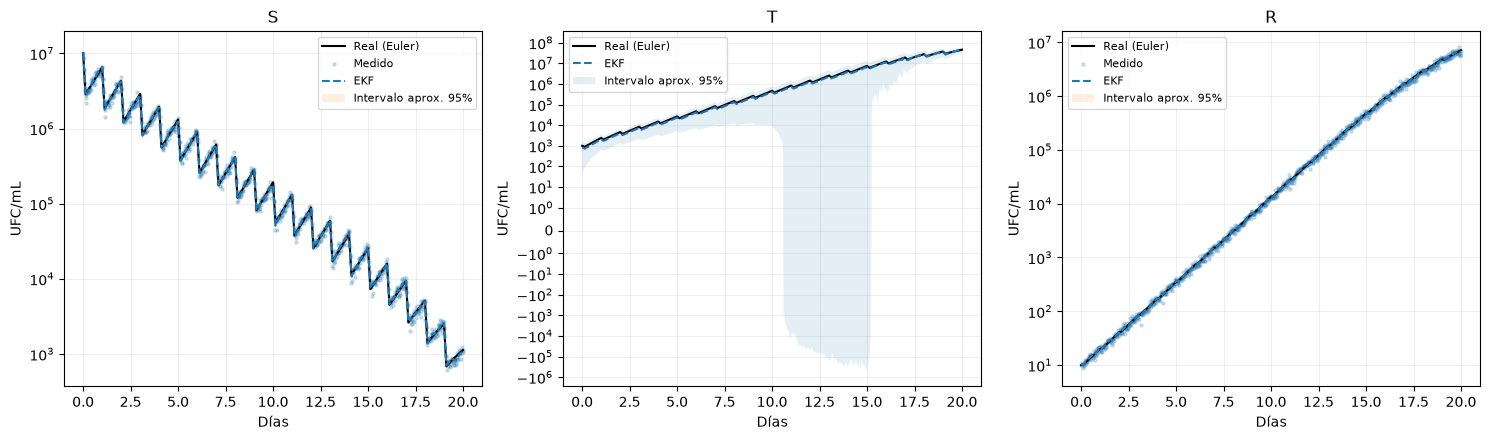

In [3]:
from src.euler_model import step
from src.filtro_kalman import jacobiano, predecir
caso = ejecutar_experimento(medir_T=False)
F = jacobiano(lambda x: step(x, C[1], dt, parametros), caso['estimados'][0])
Q = np.diag((escenario['kalman']['q_rel'] * np.maximum(caso['estimados'][0], 1))**2)
print('H =', caso['H'], 'F =', F, 'Q =', Q, 'R inicial =', caso['R_filtro'][0], sep='\n')
print('RMSE EKF [S,T,R]:', rmse(caso['verdad'], caso['estimados']))
figura = graficar(caso)
display(figura)
plt.close(figura)


## 4. Ajustar Q y R con datos sintéticos

El modelo de Euler usado como «verdad» es determinista; por eso también probamos `q_rel=0` (Q nula). `factor_R` multiplica la varianza que supone el filtro, sin cambiar las mediciones generadas. Usamos las semillas 0–4 para buscar un RMSE bajo de T **y** una cobertura de sus intervalos cercana al 95% (entre 93.5% y 96.5%). La anchura media se informa para detectar bandas excesivas. Estos criterios son de este experimento, no una calibración de laboratorio.


In [4]:
resultados = []
for q in (0.0, 0.0002, 0.001, 0.005, 0.02):
    for factor in (0.5, 0.75, 1.0, 2.0):
        errores, coberturas, anchuras = [], [], []
        for semilla in range(5):
            caso = ejecutar_experimento(medir_T=False, semilla=semilla,
                                        q_rel=q, factor_R=factor)
            sd_T = np.sqrt(np.maximum(caso['P'][:, 1, 1], 0))
            error_T = abs(caso['estimados'][:, 1] - caso['verdad'][:, 1])
            errores.append(rmse(caso['verdad'], caso['estimados'])[1])
            coberturas.append(np.mean(error_T <= 1.96 * sd_T))
            anchuras.append(np.mean(3.92 * sd_T))
        resultados.append((np.mean(errores), q, factor,
                           np.mean(coberturas), np.mean(anchuras)))
candidatos = [r for r in resultados if 0.935 <= r[3] <= 0.965]
if not candidatos:
    raise ValueError('La grilla no dio cobertura cercana al 95%; ampliar valores.')
mejor_error, mejor_q, mejor_factor_R, cobertura_entreno, anchura_entreno = min(candidatos)
print('q_rel, factor_R, RMSE_T, cobertura_T, anchura media_T')
for error, q, factor, cobertura, anchura in sorted(resultados)[:8]:
    print(f'{q:.4f}  {factor:.2f}  {error:.0f}  {cobertura:.3f}  {anchura:.0f}')
print('Elegido (entre los de cobertura cercana a 95%):', mejor_q, mejor_factor_R,
      'RMSE_T=', round(mejor_error), 'cobertura_T=', round(cobertura_entreno, 3))


q_rel, factor_R, RMSE_T, cobertura_T, anchura media_T
0.0002  2.00  320746  1.000  1087641
0.0000  2.00  322396  1.000  1062494
0.0010  2.00  323346  1.000  1373913
0.0010  1.00  338266  1.000  1222180
0.0002  1.00  342188  0.988  882174
0.0000  1.00  345371  0.981  844255
0.0010  0.75  348079  1.000  1169645
0.0002  0.75  352530  0.967  809515
Elegido (entre los de cobertura cercana a 95%): 0.0 0.75 RMSE_T= 356097 cobertura_T= 0.952


## 5. Validar con semillas nuevas

Las semillas 5–9 no participaron en la elección. Comparamos con el caso nominal (`q_rel=0.02`, `factor_R=1`). La convergencia se define como el primer día desde el cual el error relativo medio de T en ventanas de 24 horas permanece bajo el 10%. Informamos RMSE, cobertura y anchura media del intervalo de T: mejorar el RMSE por sí solo no basta.


In [5]:
def tiempo_convergencia_T(caso):
    error = abs(caso['estimados'][:, 1] - caso['verdad'][:, 1]) / np.maximum(caso['verdad'][:, 1], 1)
    ventana = round(1 / (caso['t'][1] - caso['t'][0]))  # 24 horas
    media = np.convolve(error, np.ones(ventana) / ventana, mode='valid')
    cumple_hasta_final = np.maximum.accumulate(media[::-1])[::-1] <= 0.10
    indices = np.flatnonzero(cumple_hasta_final)
    return None if len(indices) == 0 else caso['t'][indices[0] + ventana - 1]

rmse_nominal, rmse_ajustado, cobertura_T, anchura_T = [], [], [], []
for semilla in range(5, 10):
    nominal = ejecutar_experimento(medir_T=False, semilla=semilla)
    ajustado = ejecutar_experimento(medir_T=False, semilla=semilla,
                                    q_rel=mejor_q, factor_R=mejor_factor_R)
    sd_T = np.sqrt(np.maximum(ajustado['P'][:, 1, 1], 0))
    error_T = abs(ajustado['estimados'][:, 1] - ajustado['verdad'][:, 1])
    rmse_nominal.append(rmse(nominal['verdad'], nominal['estimados'])[1])
    rmse_ajustado.append(rmse(ajustado['verdad'], ajustado['estimados'])[1])
    cobertura_T.append(np.mean(error_T <= 1.96 * sd_T))
    anchura_T.append(np.mean(3.92 * sd_T))
    print(f'Semilla {semilla}: RMSE T nominal={rmse_nominal[-1]:.0f}, '
          f'ajustado={rmse_ajustado[-1]:.0f}; cobertura T={cobertura_T[-1]:.3f}; '
          f'convergencia T={tiempo_convergencia_T(ajustado)} días')
print(f'Medias de validación: RMSE nominal={np.mean(rmse_nominal):.0f}, '
      f'RMSE ajustado={np.mean(rmse_ajustado):.0f}, cobertura T={np.mean(cobertura_T):.3f}, '
      f'anchura media T={np.mean(anchura_T):.0f}')


Semilla 5: RMSE T nominal=767047, ajustado=235642; cobertura T=1.000; convergencia T=15.145833333333332 días


Semilla 6: RMSE T nominal=700071, ajustado=488150; cobertura T=0.862; convergencia T=16.916666666666664 días


Semilla 7: RMSE T nominal=719849, ajustado=466736; cobertura T=0.925; convergencia T=16.833333333333332 días


Semilla 8: RMSE T nominal=796991, ajustado=282833; cobertura T=0.983; convergencia T=10.291666666666666 días
Semilla 9: RMSE T nominal=674663, ajustado=303070; cobertura T=0.999; convergencia T=15.791666666666666 días
Medias de validación: RMSE nominal=731724, RMSE ajustado=355286, cobertura T=0.954, anchura media T=766184


## 6. Figura y datos del caso ajustado

Usamos la semilla 5, que quedó fuera de la búsqueda. Este CSV y esta figura tienen nombres distintos de los casos nominales. Una cobertura empírica cercana al 95% en datos sintéticos no demuestra que Q y R tengan esos valores en una población real.


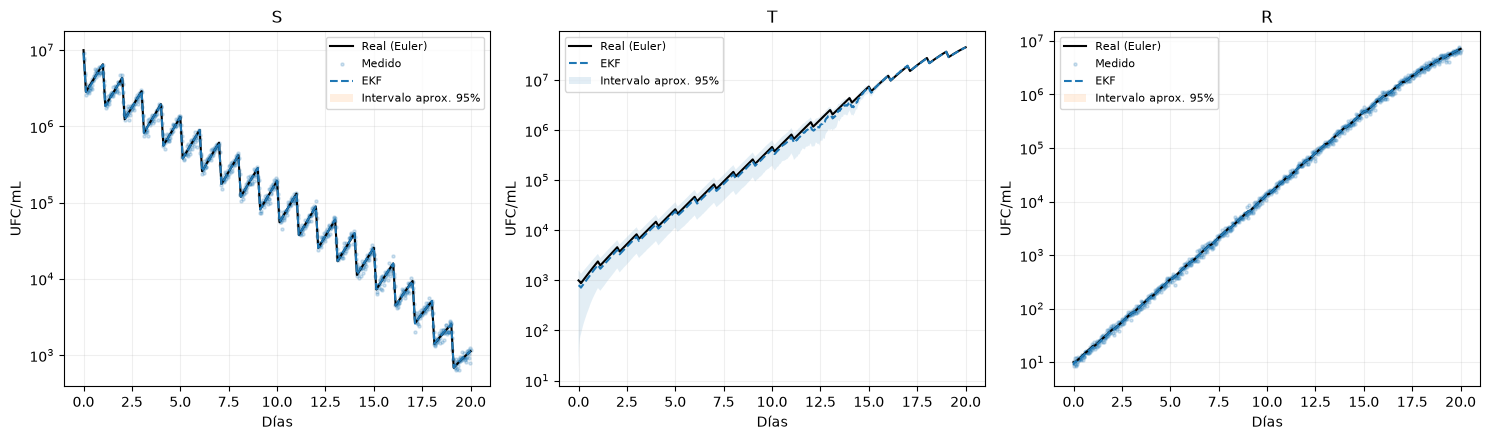

In [6]:
ajustado = ejecutar_experimento(medir_T=False, semilla=5,
                                 q_rel=mejor_q, factor_R=mejor_factor_R)
medidas_3 = np.full_like(ajustado['verdad'], np.nan)
medidas_3[:, 0], medidas_3[:, 2] = ajustado['medidas'][:, 0], ajustado['medidas'][:, 1]
tabla_ajustada = np.column_stack([ajustado['t'], ajustado['verdad'],
                                  medidas_3, ajustado['estimados']])
np.savetxt(raiz / 'data/persona3/ajustado_sin_T.csv', tabla_ajustada,
           delimiter=',', comments='',
           header='dias,S_real,T_real,R_real,S_medida,T_medida,R_medida,S_EKF,T_EKF,R_EKF')
figura = graficar(ajustado)
figura.savefig(raiz / 'figures/persona3/ajustado_sin_T.png', dpi=150)
display(figura)
plt.close(figura)


## 7. Pronóstico a 24 horas
Desde el día 10 propagamos la última estimación con las dosis programadas y sin mirar mediciones posteriores. Se compara con Euler solo para validar el pronóstico.

In [7]:
indice = round(10 / dt)
pasos = round(1 / dt)
pronostico = predecir(ajustado['estimados'][indice], ajustado['t'][indice],
                      pasos, dt, parametros, escenario)
real_manana = ajustado['verdad'][indice + pasos]
print('Pronóstico [S,T,R]:', pronostico)
print('Real [S,T,R]:', real_manana)
print('Fracción R pronosticada:', pronostico[2] / pronostico.sum())
print('Fracción R real:', real_manana[2] / real_manana.sum())


Pronóstico [S,T,R]: [131483.22001125 733001.7156353   27953.6454504 ]
Real [S,T,R]: [131266.67499496 822240.90855875  27960.21670434]
Fracción R pronosticada: 0.031322766678283716
Fracción R real: 0.028488165069695204


## 8. Conclusiones y límites
- El caso principal estima T sin observarla; S y R tienen ruido gaussiano sintético.
- Se evalúan error, convergencia, cobertura e influencia de Q y R con semillas distintas para ajuste y validación.
- El pronóstico usa únicamente el estado estimado y el calendario de dosis.
- Los intervalos son aproximados. Q nula puede elegirse aquí porque verdad y predicción usan el mismo Euler determinista; no implica que un experimento real carezca de ruido.